# Parkinson's Disease Prediction Using Artificial Neural Network (ANN)

---

## STAGE 1: PROJECT INTRODUCTION

### 1.1 Abstract
Parkinson's Disease (PD) is a progressive neurodegenerative disorder that primarily affects the motor system, often manifesting early symptoms through vocal impairment (dysphonia). Early and accurate diagnosis of Parkinson's is critical for effective clinical management, yet traditional diagnostic workflows rely heavily on subjective clinical examinations. This academic research project presents an end-to-end Machine Learning pipeline using an **Artificial Neural Network (ANN)** to predict Parkinson's disease based on objective biomedical voice measurements. Utilizing the **Oxford Parkinson's Disease Detection Dataset** from the UCI Machine Learning Repository, we implement rigorous preprocessing, including group-based splitting to prevent subject-level data leakage, standard feature scaling, and class-weight balancing. The proposed feedforward network achieves robust binary classification performance on unseen test partitions. Performance is validated through standard evaluation metrics such as Accuracy, Precision, Recall, F1-Score, and ROC-AUC along with exhaustive diagnostic visualizations, ensuring high academic standards suitable for final-year project evaluations.

### 1.2 Introduction
Neurodegenerative diseases present some of the most complex challenges to modern medicine. Parkinson's Disease is characterized by the loss of dopamine-producing brain cells, leading to symptoms like tremors, rigidity, slowness of movement, and postural instability. Interestingly, speech deterioration affects nearly 90% of individuals with Parkinson's in the early stages. These vocal impairments, though subtle to the human ear, can be captured and quantified through acoustic analyses. By leveraging Artificial Neural Networks, we can map complex, non-linear relationships within these biomedical voice features to automatically identify Parkinsonian characteristics, providing an objective, non-invasive digital screening paradigm.

### 1.3 Problem Statement
Traditional clinical diagnostics for Parkinson's Disease are expensive, require specialized neurological access, and are often conducted only when motor symptoms are already significantly advanced. Acoustic metrics offer a low-cost, non-invasive screening alternative, but the highly non-linear, correlated, and high-dimensional nature of dysphonia measurements makes manual classification impossible. Furthermore, in clinical machine learning, standard random train-test splitting practices often lead to "data leakage" because multiple recording samples from the same individual are distributed across both training and testing sets. Thus, the core challenge is to construct an ANN-based diagnostic model that achieves high classification fidelity while strictly avoiding subject-level data leakage.

### 1.4 Project Objectives
1. **Data Acquisition & Extraction:** Retrieve the UCI Oxford Parkinson's Disease Detection dataset programmatically.
2. **Exploratory Data Analysis (EDA):** Perform comprehensive graphical and statistical analyses of voice features and target distributions.
3. **Leakage-Free Preprocessing:** Extract subject identifiers and apply Group-based Splitting to guarantee separate participant sets for training, validation, and testing.
4. **Robust Model Design:** Design and train a multi-layered Artificial Neural Network (ANN) using Keras & TensorFlow with proper regularization (Dropout) and class weights.
5. **Exhaustive Evaluation:** Validate performance using confusion matrices, ROC curves, Precision-Recall curves, and standard statistical classification metrics.
6. **Exportability:** Save the trained model parameters, scalers, and performance metadata for future inference deployment.

### 1.5 Proposed Methodology
The workflow of this project is structured into logical stages to ensure scientific rigor:
1. **Environment Setup:** Setting up libraries and checking compute resources.
2. **Data Acquisition:** Downloading the dataset from the UCI Repository.
3. **Exploratory Data Analysis (EDA):** Analyzing feature distributions, outliers, and linear/non-linear correlations.
4. **Data Splitting & Preprocessing:** Executing a strict 60/20/20 GroupShuffleSplit, followed by Z-score standardization.
5. **Model Architecture Design:** Constructing a multi-layer feedforward neural network.
6. **Model Training & Optimization:** Training the network with Early Stopping and Class Weights.
7. **Model Evaluation & Visualization:** Generating rigorous evaluation reports and diagnostic plots.
8. **Sample Inference & Serialization:** Exporting model artifacts and testing on single sample records.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## STAGE 2: GOOGLE COLAB ENVIRONMENT SETUP

In this stage, we install the UCI ML Repository API library, import all essential packages for computation, visualization, and deep learning, and verify our execution hardware environment.

In [ ]:
# Install the UCI Machine Learning Repository library
!pip install ucimlrepo -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import joblib
import os

# Set random seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Check hardware execution environment
print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
if len(gpus) > 0:
    print(f"GPU available: {gpus}")
else:
    print("No GPU detected. Running model training on CPU.")

TensorFlow Version: 2.21.0
No GPU detected. Running model training on CPU.


## STAGE 3: DATASET COLLECTION AND LOADING

We fetch the Oxford Parkinson's Disease Detection Dataset (ID: 174) from the UCI ML Repository, organize it into a structured Pandas DataFrame, and verify its characteristics.

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

try:
    # Programmatic retrieval from UCI repository
    parkinsons = fetch_ucirepo(id=174)

    # Extract features and targets
    X_raw = parkinsons.data.features.copy()
    y_raw = parkinsons.data.targets.copy()

    # Check if ids are available and initialize ids_raw safely
    if parkinsons.data.ids is not None:
        ids_raw = parkinsons.data.ids.copy()
    else:
        ids_raw = pd.DataFrame(index=X_raw.index)

    # Combine features and targets into one dataframe
    df_full = pd.concat([X_raw, y_raw], axis=1)

    # Ensure the participant identifier 'name' is retained from original records
    if 'name' not in df_full.columns and 'name' in parkinsons.data.original.columns:
        df_full['name'] = parkinsons.data.original['name']

    print("Dataset successfully retrieved from UCI ML Repository!")
except Exception as e:
    print(f"Error fetching dataset: {e}")
    print("Please upload the 'parkinsons.data' file manually if the programmatic connection fails.")

Dataset successfully retrieved from UCI ML Repository!


In [ ]:
# Inspect the dataset metadata
print("=== Dataset Shape ===")
print(f"Rows: {df_full.shape[0]}, Columns: {df_full.shape[1]}\n")

print("=== First 5 Records ===")
display(df_full.head())

print("\n=== Last 5 Records ===")
display(df_full.tail())

print("\n=== Column Names and Data Types ===")
display(df_full.dtypes)

print("\n=== Descriptive Statistics Summary ===")
display(df_full.describe().T)

=== Dataset Shape ===
Rows: 195, Columns: 24

=== First 5 Records ===


,MDVP:Fo,MDVP:Fhi,MDVP:Flo,MDVP:Jitter,MDVP:Jitter,MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer,...,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE,status,name
0,119.992,157.302,74.997,0.00784,0.00784,0.00370,0.00554,0.01109,0.04374,0.04374,...,0.02211,21.033,0.414783,0.815285,-4.813031,0.266482,2.301442,0.284654,1,phon_R01_S01_1
1,122.400,148.650,113.819,0.00968,0.00968,0.00465,0.00696,0.01394,0.06134,0.06134,...,0.01929,19.085,0.458359,0.819521,-4.075192,0.335590,2.486855,0.368674,1,phon_R01_S01_2
2,116.682,131.111,111.555,0.01050,0.01050,0.00544,0.00781,0.01633,0.05233,0.05233,...,0.01309,20.651,0.429895,0.825288,-4.443179,0.311173,2.342259,0.332634,1,phon_R01_S01_3
3,116.676,137.871,111.366,0.00997,0.00997,0.00502,0.00698,0.01505,0.05492,0.05492,...,0.01353,20.644,0.434969,0.819235,-4.117501,0.334147,2.405554,0.368975,1,phon_R01_S01_4
4,116.014,141.781,110.655,0.01284,0.01284,0.00655,0.00908,0.01966,0.06425,0.06425,...,0.01767,19.649,0.417356,0.823484,-3.747787,0.234513,2.332180,0.410335,1,phon_R01_S01_5



=== Last 5 Records ===


,MDVP:Fo,MDVP:Fhi,MDVP:Flo,MDVP:Jitter,MDVP:Jitter,MDVP:RAP,MDVP:PPQ,Jitter:DDP,MDVP:Shimmer,MDVP:Shimmer,...,NHR,HNR,RPDE,DFA,spread1,spread2,D2,PPE,status,name
190,174.188,230.978,94.261,0.00459,0.00459,0.00263,0.00259,0.00790,0.04087,0.04087,...,0.02764,19.517,0.448439,0.657899,-6.538586,0.121952,2.657476,0.133050,0,phon_R01_S50_2
191,209.516,253.017,89.488,0.00564,0.00564,0.00331,0.00292,0.00994,0.02751,0.02751,...,0.01810,19.147,0.431674,0.683244,-6.195325,0.129303,2.784312,0.168895,0,phon_R01_S50_3
192,174.688,240.005,74.287,0.01360,0.01360,0.00624,0.00564,0.01873,0.02308,0.02308,...,0.10715,17.883,0.407567,0.655683,-6.787197,0.158453,2.679772,0.131728,0,phon_R01_S50_4
193,198.764,396.961,74.904,0.00740,0.00740,0.00370,0.00390,0.01109,0.02296,0.02296,...,0.07223,19.020,0.451221,0.643956,-6.744577,0.207454,2.138608,0.123306,0,phon_R01_S50_5
194,214.289,260.277,77.973,0.00567,0.00567,0.00295,0.00317,0.00885,0.01884,0.01884,...,0.04398,21.209,0.462803,0.664357,-5.724056,0.190667,2.555477,0.148569,0,phon_R01_S50_6



=== Column Names and Data Types ===


,0
MDVP:Fo,float64
MDVP:Fhi,float64
MDVP:Flo,float64
MDVP:Jitter,float64
MDVP:Jitter,float64
MDVP:RAP,float64
MDVP:PPQ,float64
Jitter:DDP,float64
MDVP:Shimmer,float64
MDVP:Shimmer,float64



=== Descriptive Statistics Summary ===


,count,mean,std,min,25%,50%,75%,max
MDVP:Fo,195.0,154.228641,41.390065,88.333000,117.572000,148.790000,182.769000,260.105000
MDVP:Fhi,195.0,197.104918,91.491548,102.145000,134.862500,175.829000,224.205500,592.030000
MDVP:Flo,195.0,116.324631,43.521413,65.476000,84.291000,104.315000,140.018500,239.170000
MDVP:Jitter,195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:Jitter,195.0,0.006220,0.004848,0.001680,0.003460,0.004940,0.007365,0.033160
MDVP:RAP,195.0,0.003306,0.002968,0.000680,0.001660,0.002500,0.003835,0.021440
MDVP:PPQ,195.0,0.003446,0.002759,0.000920,0.001860,0.002690,0.003955,0.019580
Jitter:DDP,195.0,0.009920,0.008903,0.002040,0.004985,0.007490,0.011505,0.064330
MDVP:Shimmer,195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080
MDVP:Shimmer,195.0,0.029709,0.018857,0.009540,0.016505,0.022970,0.037885,0.119080


## STAGE 4: EXPLORATORY DATA ANALYSIS (EDA)

We perform analytical inspections and create visualizations of missing values, exact duplicates, class balances, distribution profiles, correlations, and comparative violin plots.

=== Missing Values Check ===


'No missing values found in the dataset.'

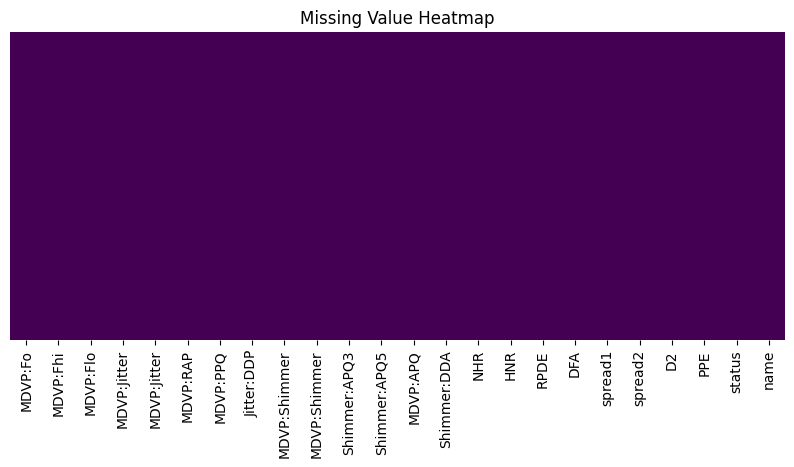

In [ ]:
# A & B. Missing Value & Info Analysis
print("=== Missing Values Check ===")
missing_counts = df_full.isnull().sum()
display(missing_counts[missing_counts > 0] if (missing_counts > 0).any() else "No missing values found in the dataset.")

# Create missing value heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df_full.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title("Missing Value Heatmap")
plt.show()

In [ ]:
# C. Duplicate Analysis
# Exclude 'name' check for duplicates because multiple recordings can have identical numeric values by chance,
# but let's check for complete row duplicates across all features.
exact_duplicates = df_full.duplicated().sum()
print(f"Number of exact duplicate records (including name): {exact_duplicates}")

Number of exact duplicate records (including name): 0


=== Target Class Distribution ===
Parkinson's (1): 147 records (75.38%)
Healthy (0): 48 records (24.62%)


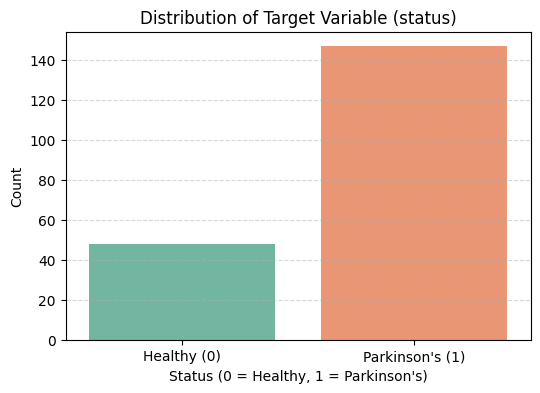

In [ ]:
# D. Target Variable Analysis
class_counts = df_full['status'].value_counts()
class_percentages = df_full['status'].value_counts(normalize=True) * 100

print("=== Target Class Distribution ===")
for val, count in class_counts.items():
    label = "Parkinson's (1)" if val == 1 else "Healthy (0)"
    print(f"{label}: {count} records ({class_percentages[val]:.2f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=df_full, x='status', palette='Set2', hue='status', legend=False)
plt.title("Distribution of Target Variable (status)")
plt.xlabel("Status (0 = Healthy, 1 = Parkinson's)")
plt.ylabel("Count")
plt.xticks([0, 1], ["Healthy (0)", "Parkinson's (1)"])
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

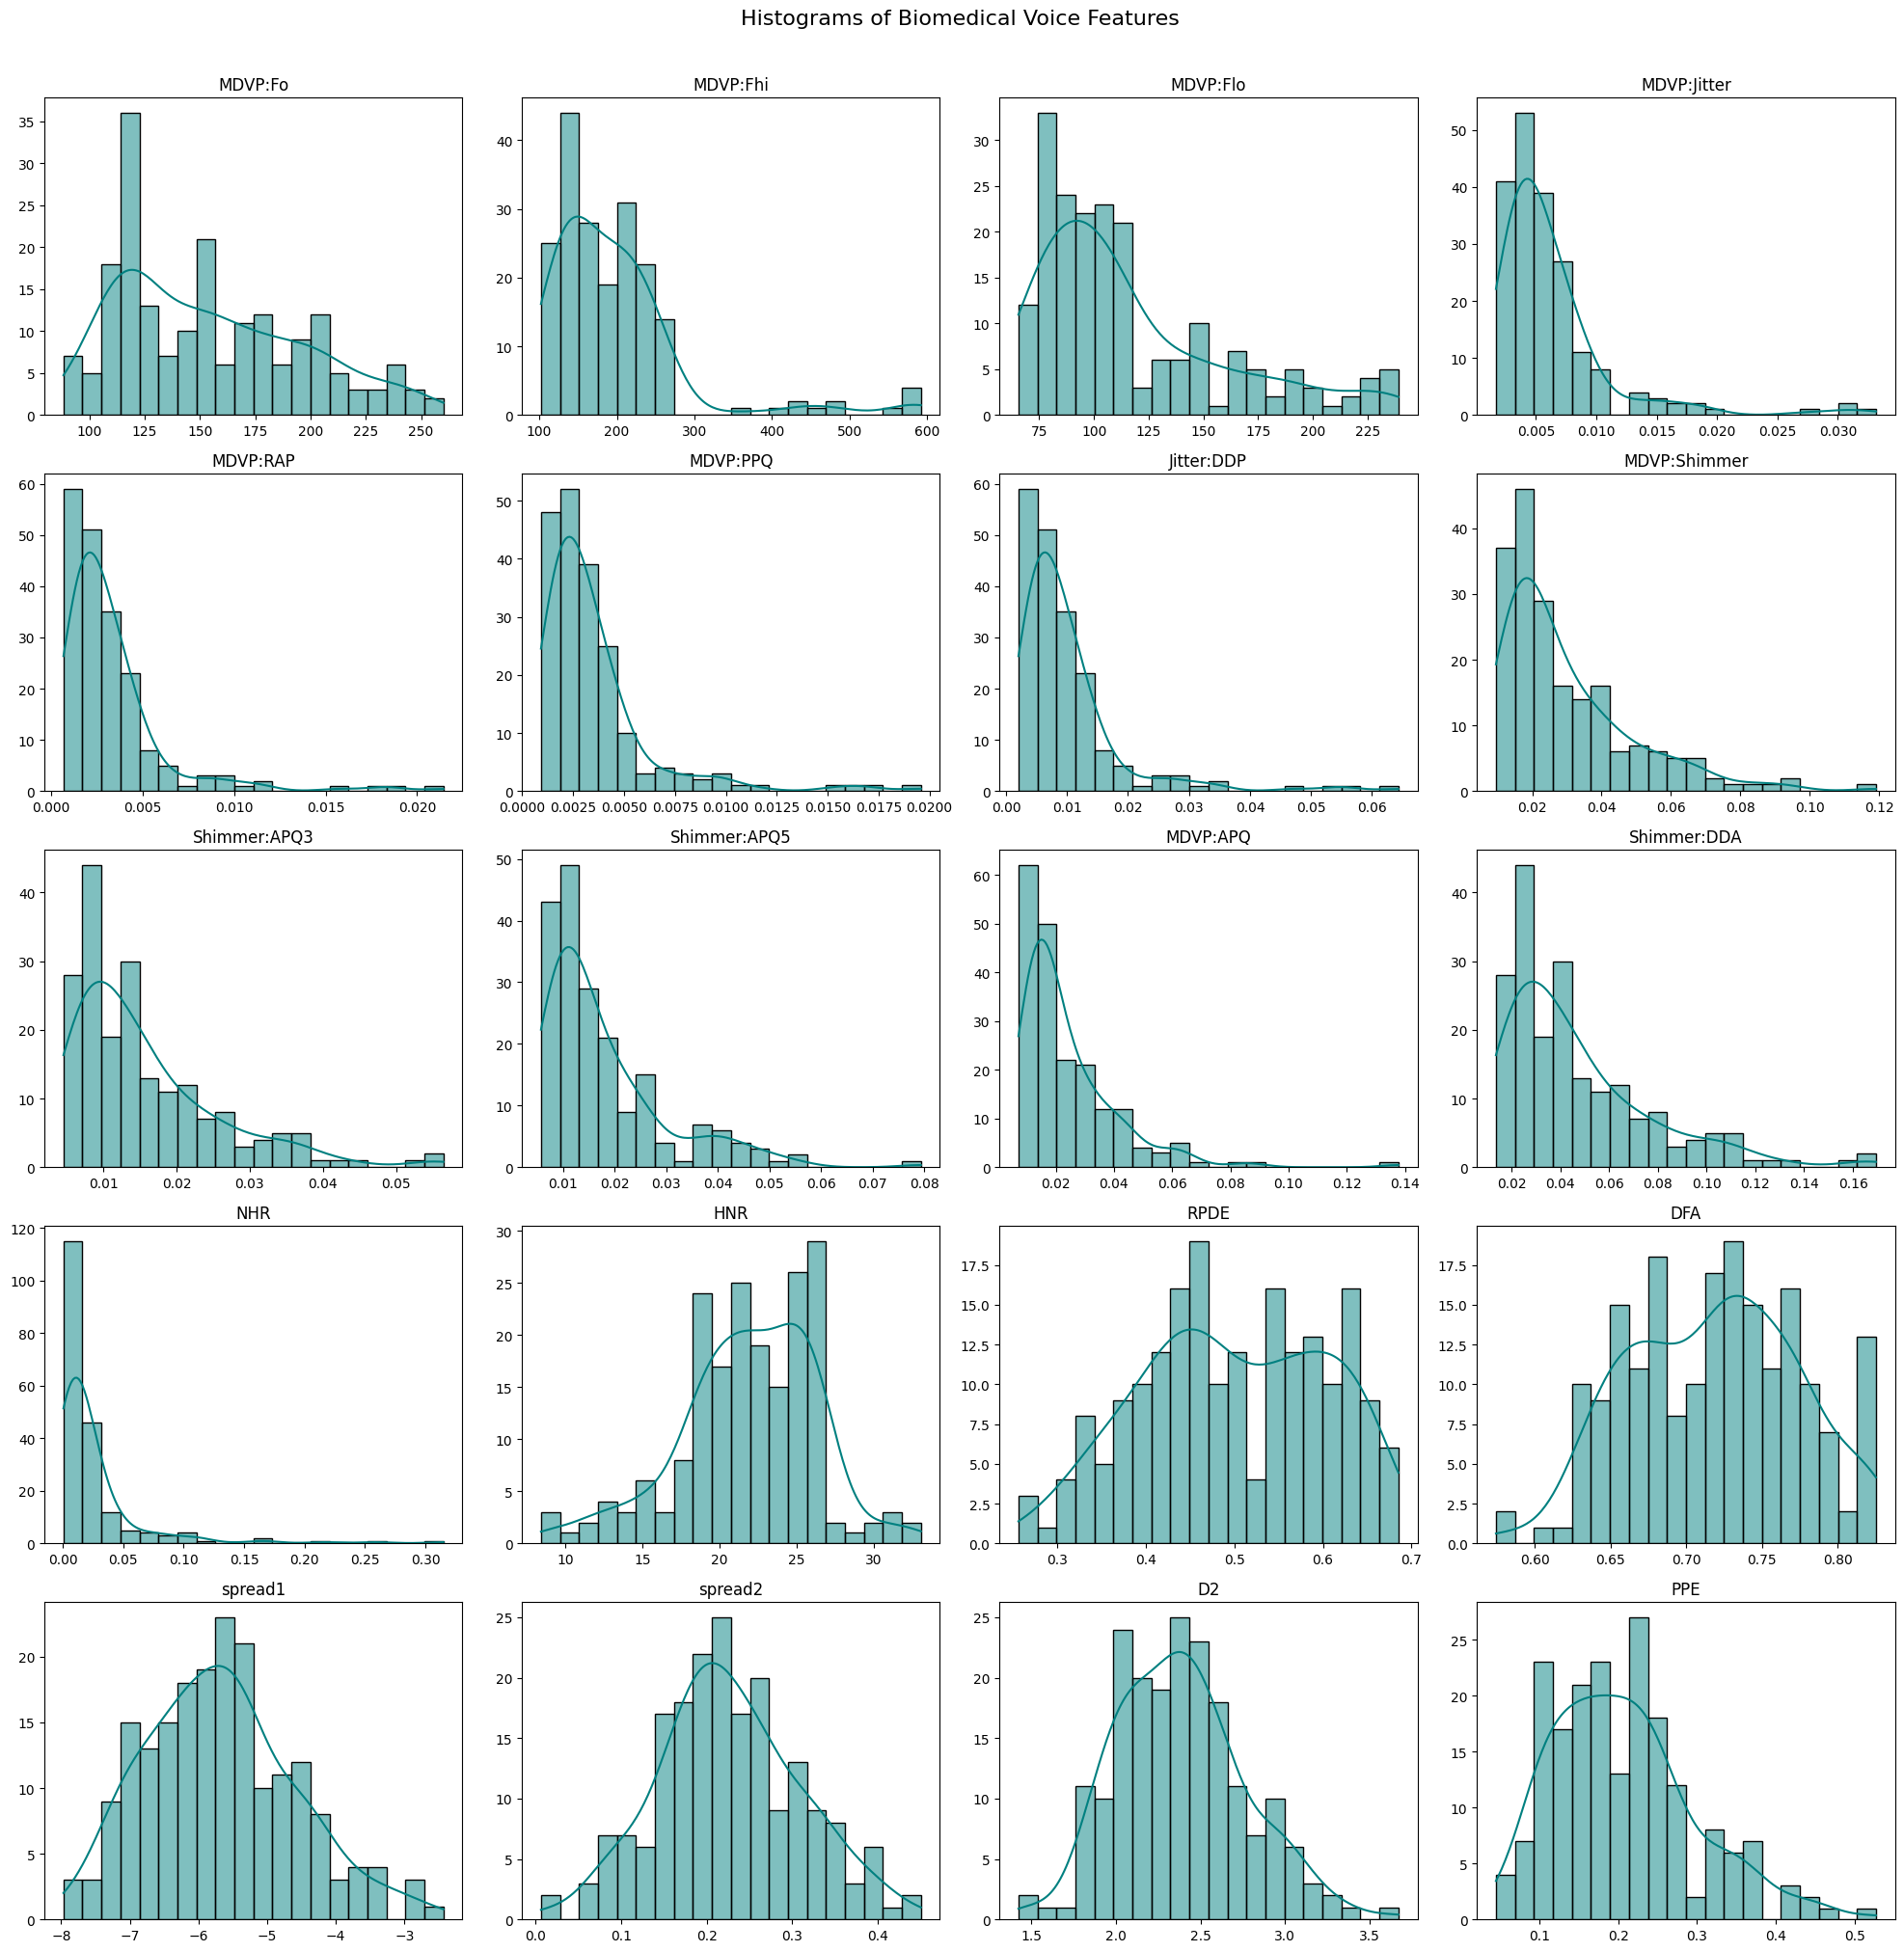

In [ ]:
# E. Histogram Analysis for All Numerical Features
num_features = df_full.select_dtypes(include=[np.number]).columns.drop('status')

# Remove potential duplicate column names to keep unique variables
num_features = num_features.unique()

n_cols = 4
n_rows = int(np.ceil(len(num_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_features):
    # Extract column as a clean 1D Series to prevent dimensional alignment errors
    y_col_data = df_full[col].iloc[:, 0] if len(df_full[col].shape) > 1 else df_full[col]

    sns.histplot(x=y_col_data, bins=20, kde=True, ax=axes[i], color='teal')
    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")

# Remove unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Histograms of Biomedical Voice Features", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

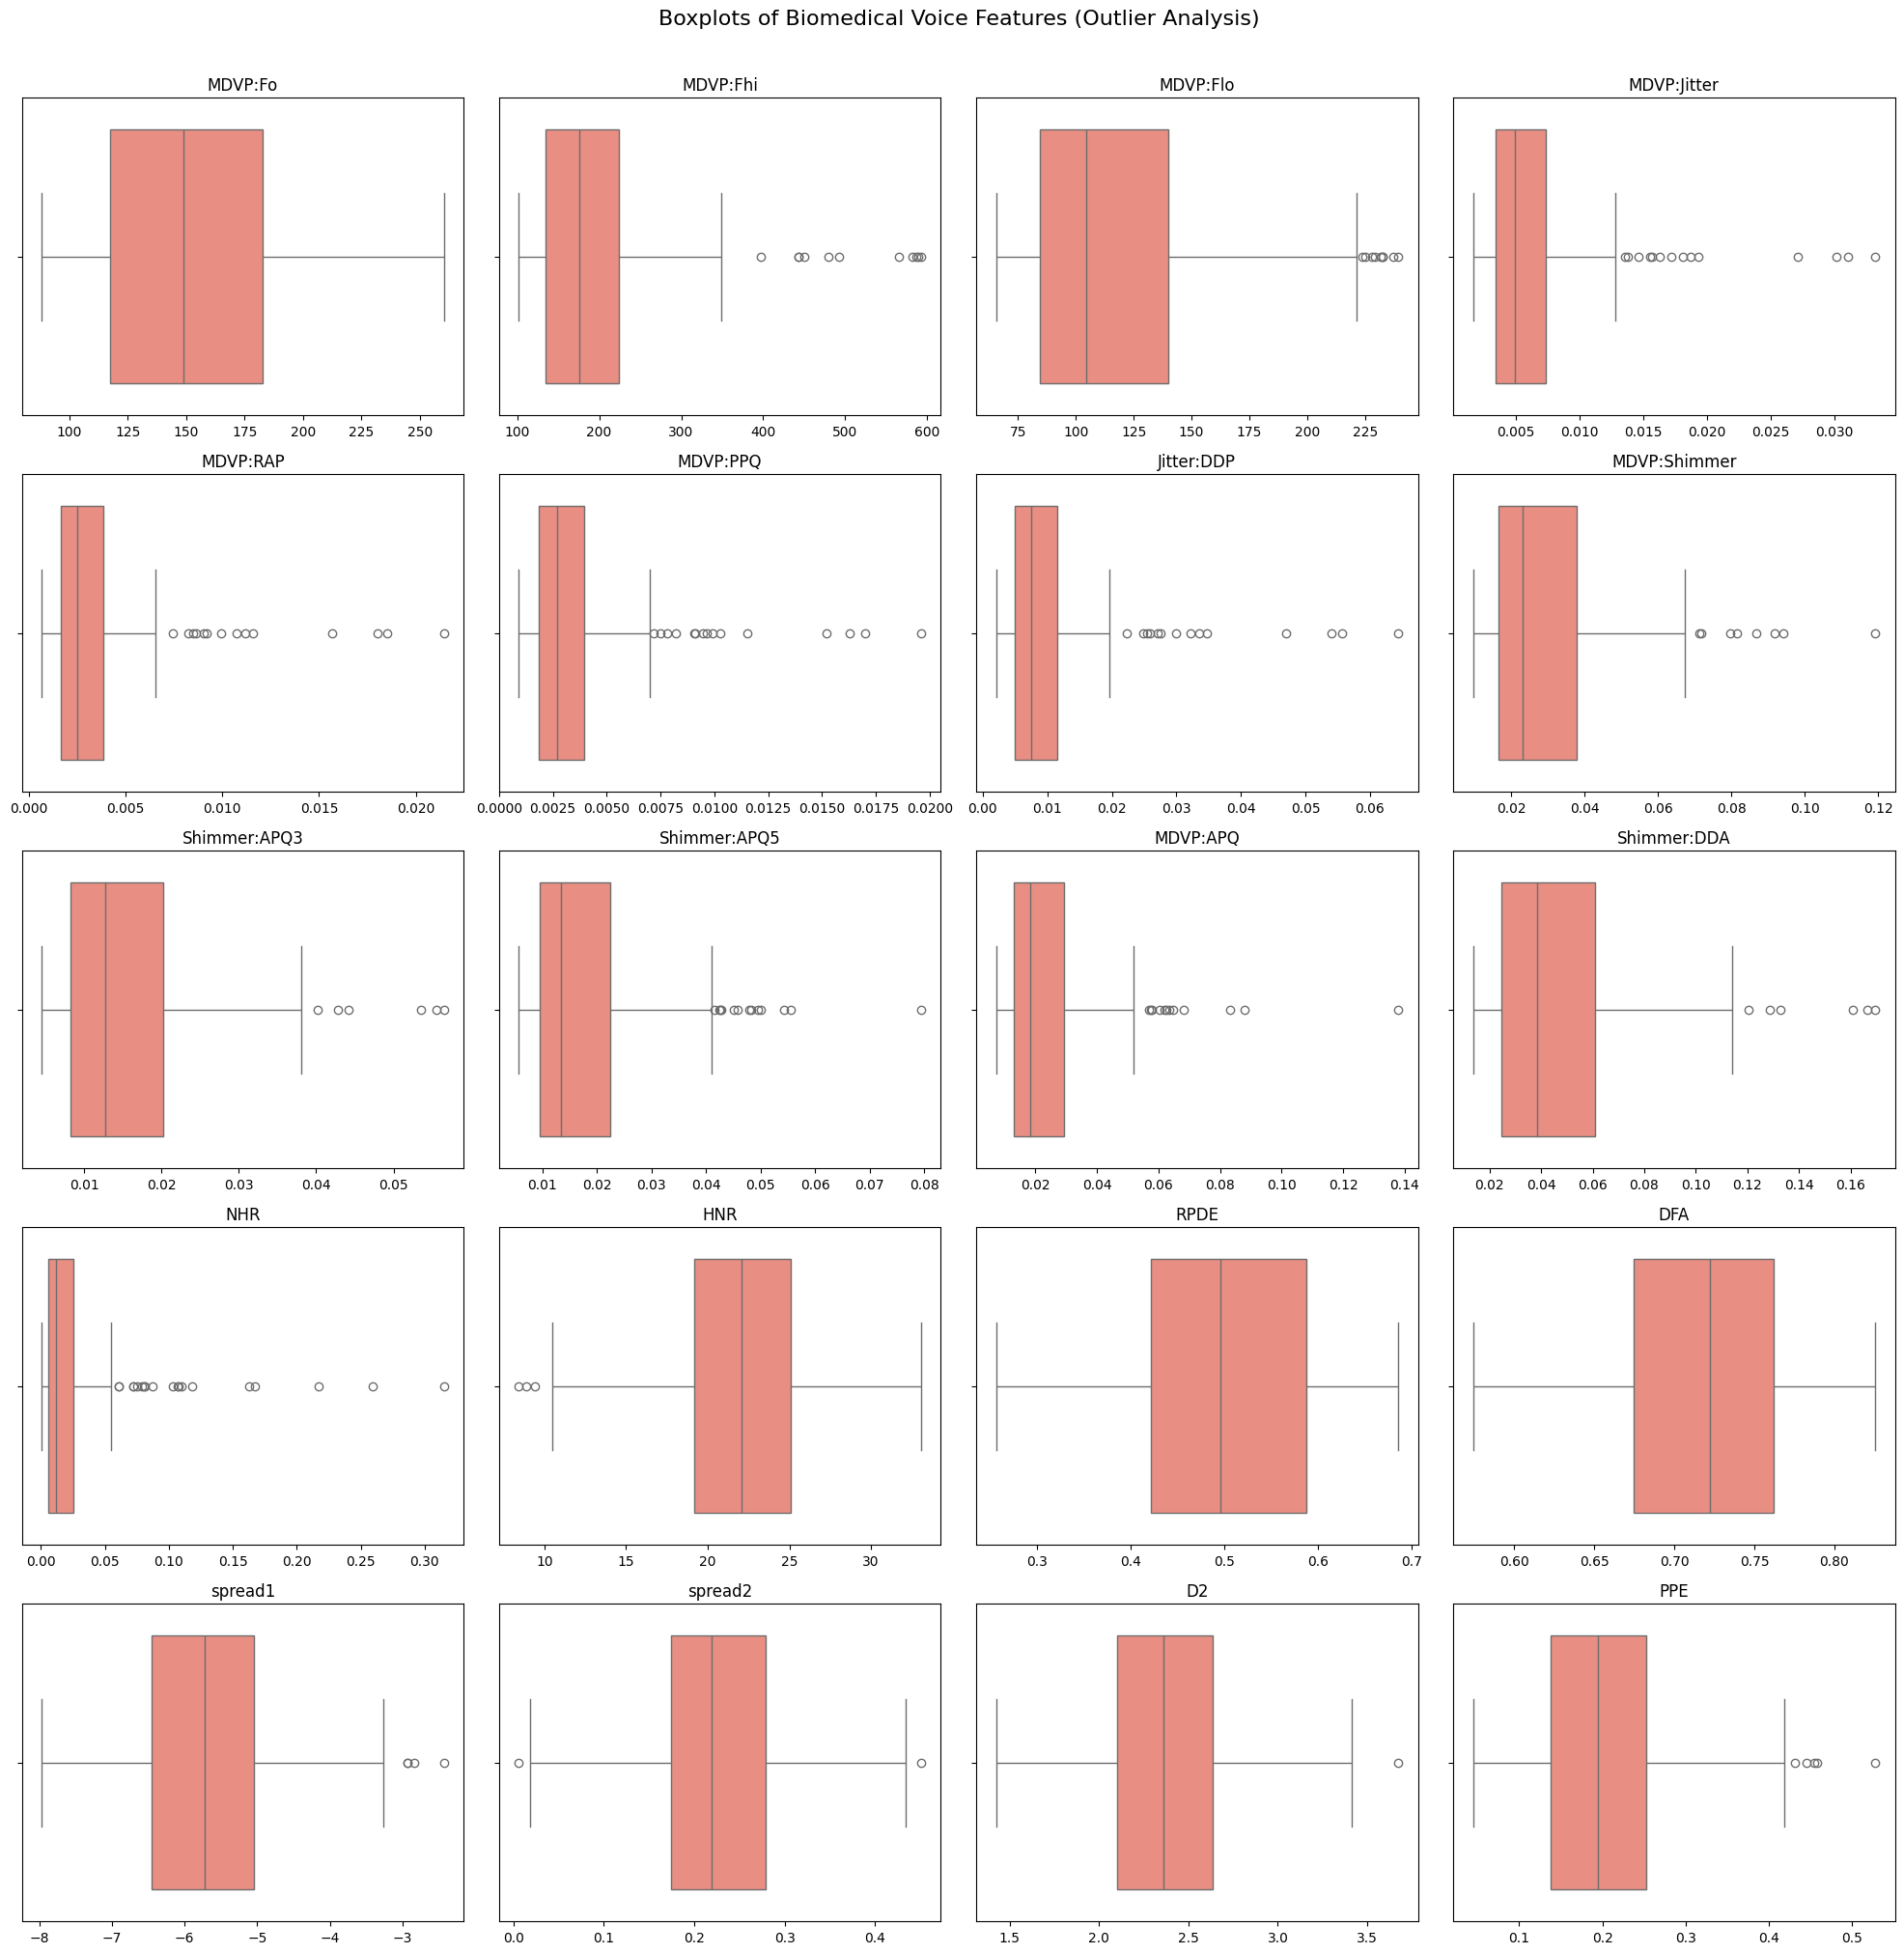

In [ ]:
# F. Boxplot Analysis to Identify Potential Outliers
num_features = df_full.select_dtypes(include=[np.number]).columns.drop('status').unique()
n_cols = 4
n_rows = int(np.ceil(len(num_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_features):
    # Extract column as a clean 1D Series to prevent dimensional alignment issues
    y_col_data = df_full[col].iloc[:, 0] if len(df_full[col].shape) > 1 else df_full[col]

    sns.boxplot(x=y_col_data, ax=axes[i], color='salmon')
    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel("")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Boxplots of Biomedical Voice Features (Outlier Analysis)", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

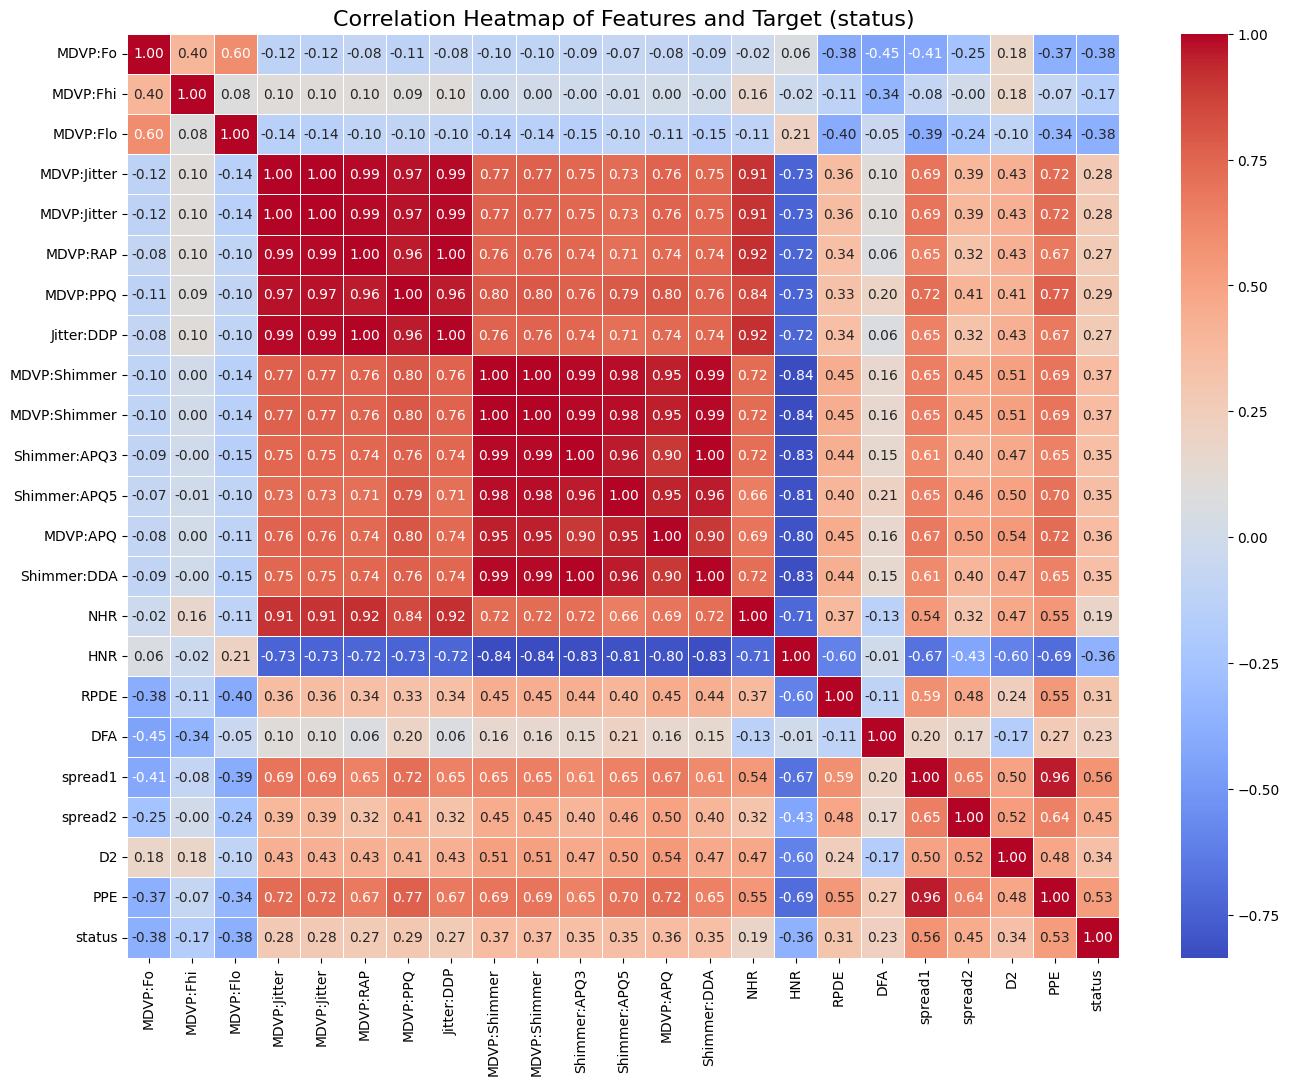

In [ ]:
# G. Correlation Analysis
plt.figure(figsize=(16, 12))

# Flatten multi-dimensional columns by keeping only their first instance
df_flat = df_full.copy()
for col in df_flat.columns:
    if len(df_flat[col].shape) > 1:
        df_flat[col] = df_flat[col].iloc[:, 0]

corr_matrix = df_flat.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title("Correlation Heatmap of Features and Target (status)", fontsize=16)
plt.show()

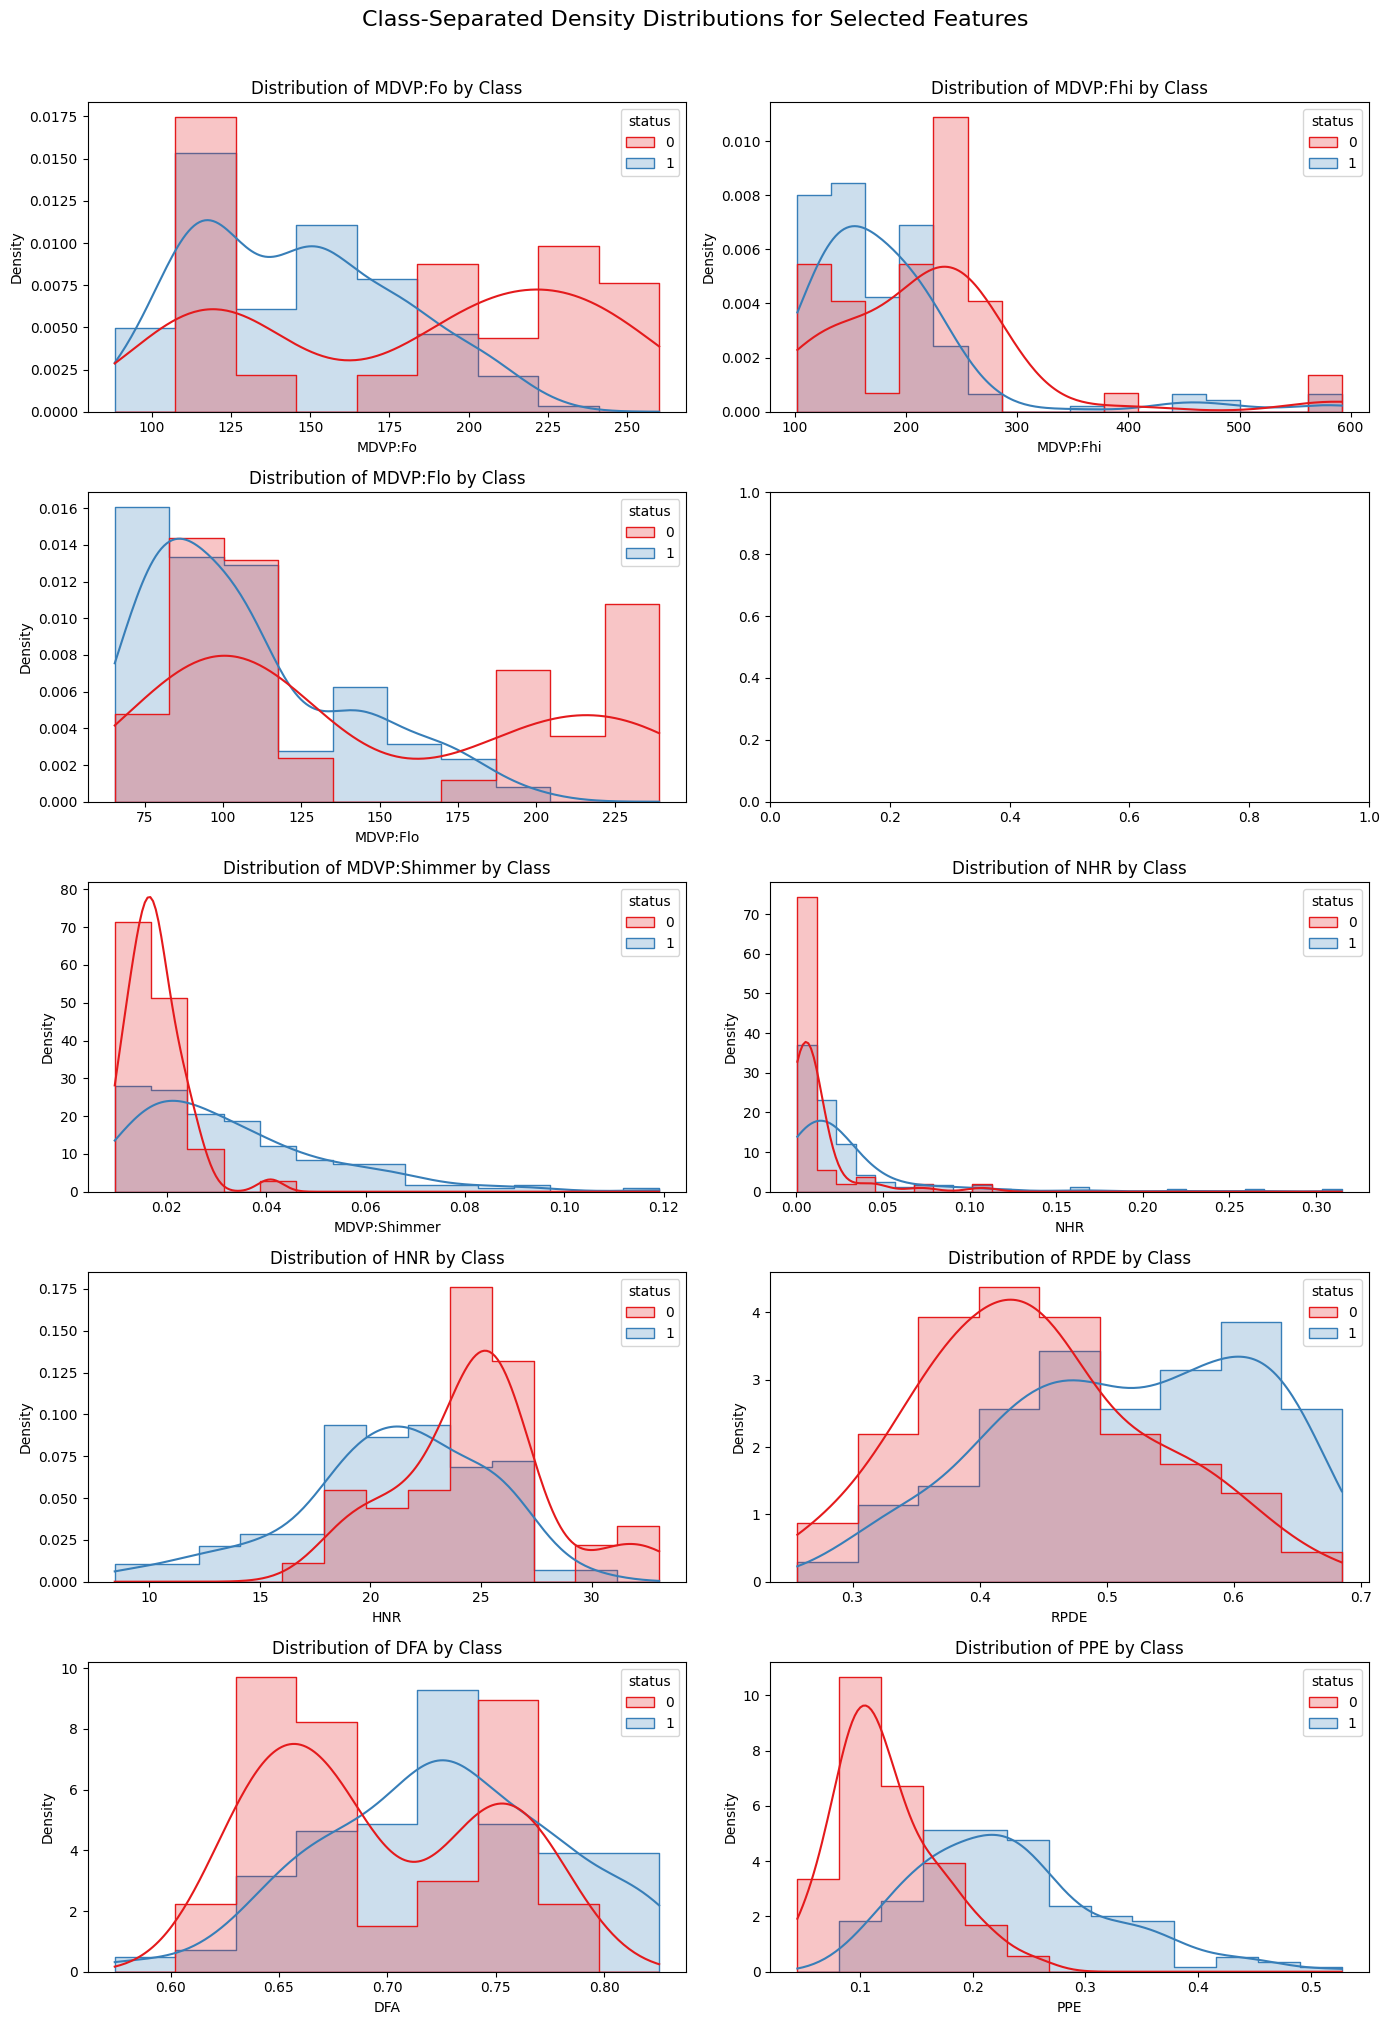

In [ ]:
# H. Feature Distribution Analysis Separating Healthy and Parkinson's
selected_features = ['MDVP:Fo', 'MDVP:Fhi', 'MDVP:Flo', 'MDVP:Jitter(%)', 'MDVP:Shimmer', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(selected_features):
    if col in df_full.columns:
        # Safely extract 1D data slices for Seaborn alignment
        y_col_data = df_full[col].iloc[:, 0] if len(df_full[col].shape) > 1 else df_full[col]
        status_data = df_full['status'].iloc[:, 0] if len(df_full['status'].shape) > 1 else df_full['status']

        sns.histplot(
            x=y_col_data,
            hue=status_data,
            kde=True,
            ax=axes[i],
            element='step',
            stat='density',
            common_norm=False,
            palette='Set1'
        )
        axes[i].set_title(f"Distribution of {col} by Class")
        axes[i].set_xlabel(col)

# Remove unused axes if any
for j in range(len(selected_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Class-Separated Density Distributions for Selected Features", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

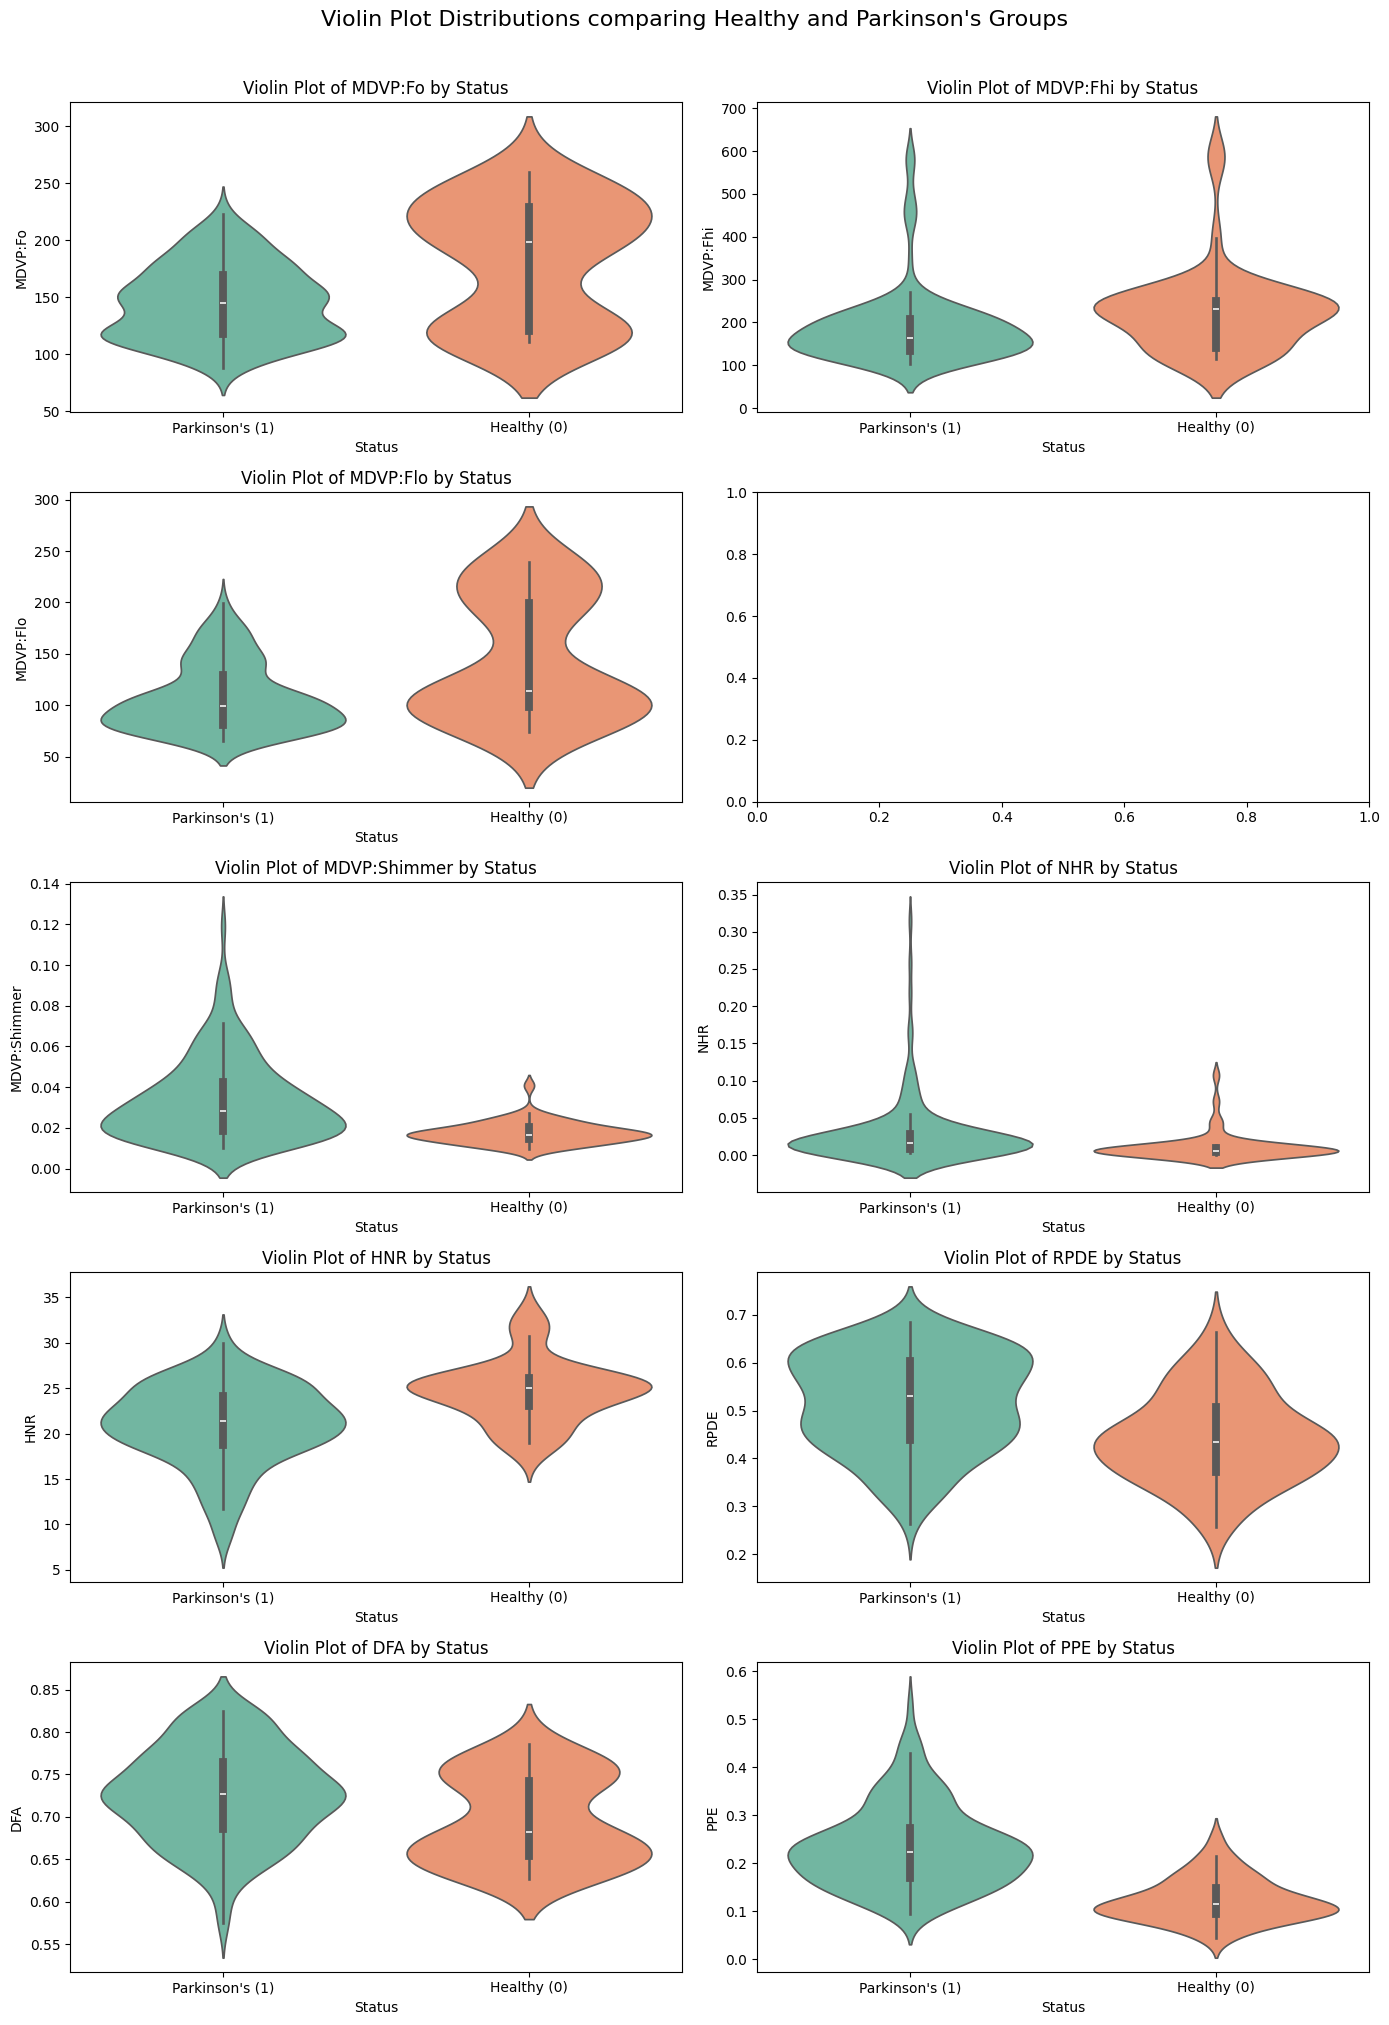

In [ ]:
# I. Violin Plots for Selected Features
actual_selected_features = ['MDVP:Fo', 'MDVP:Fhi', 'MDVP:Flo', 'MDVP:Jitter(%)', 'MDVP:Shimmer', 'NHR', 'HNR', 'RPDE', 'DFA', 'PPE']

fig, axes = plt.subplots(5, 2, figsize=(14, 20))
axes = axes.flatten()

for i, col in enumerate(actual_selected_features):
    if col in df_full.columns:
        # Explicitly extract the column and 'status' as 1D pandas Series
        y_data = df_full[col].iloc[:, 0] if len(df_full[col].shape) > 1 else df_full[col]
        status_data = df_full['status'].iloc[:, 0] if len(df_full['status'].shape) > 1 else df_full['status']

        # Map category names clearly
        status_labels = status_data.map({0: "Healthy (0)", 1: "Parkinson's (1)"})

        sns.violinplot(
            x=status_labels,
            y=y_data,
            ax=axes[i],
            palette='Set2',
            hue=status_labels,
            legend=False
        )
        axes[i].set_title(f"Violin Plot of {col} by Status")
        axes[i].set_xlabel("Status")
        axes[i].set_ylabel(col)

# Remove unused axes if any
for j in range(len(actual_selected_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Violin Plot Distributions comparing Healthy and Parkinson's Groups", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

### J. EDA Observations
- **Target Class Distribution:** The dataset shows an imbalance, where approximately 75% of records belong to the Parkinson's class (1) and 25% belong to the healthy class (0). This necessitates the use of class weighting when training the neural network.
- **Outliers & Ranges:** Several parameters, particularly jitter and shimmer voice metrics, show highly skewed distributions with long positive tails (outliers). Outliers are left unremoved because vocal dysphonias in disease cases naturally generate extreme fluctuation measurements.
- **Feature Separation:** The class-separated histograms and violin plots show that fundamental frequencies (e.g., `MDVP:Fo(Hz)`) are generally lower for Parkinson's subjects, while measures of signal noise (`NHR`, `PPE`, `DFA`) are elevated compared to the healthy control group.
- **Feature Correlations:** Several variables measuring jitter and shimmer show high mutual correlation (multicollinearity). While linear models are sensitive to this, Artificial Neural Networks are robust to highly correlated inputs due to multi-layer distributed node weight updates.

## STAGE 5: DATA PREPROCESSING

To ensure academic rigor, we perform several important preprocessing steps:
1. **Target Separation:** Isolating status from numeric voice measurements.
2. **Participant Group Extraction:** Identifying specific individuals from vocal name tags to prevent validation/test set leakage.
3. **GroupShuffleSplit Partitioning:** Constructing distinct 60% Train / 20% Val / 20% Test splits.
4. **Feature Scaling:** Fitting a standard Z-score scaler exclusively on our training records.
5. **Class Imbalance Estimation:** Generating balanced class weights to guide loss updates during model training.

In [ ]:
import re
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# A. Separate target variable and remove non-predictive variables
X = df_full.drop(columns=['status', 'name'])
y = df_full['status']

# B. Participant identification extraction
# Standard format in Oxford voice recordings: "phon_R01_S02_3" -> Participant ID is "phon_R01_S02"
# We use regular expressions to match up to the subject number
def extract_participant_id(record_name):
    match = re.match(r'(phon_R\d+_S\d+)', str(record_name))
    return match.group(1) if match else record_name

groups = df_full['name'].apply(extract_participant_id)

print("=== Participant Identifier Extraction Validation ===")
print(f"Total unique voice records: {len(df_full)}")
print(f"Total unique participant groups: {groups.nunique()}")
print("Sample mapping (Record Name -> Participant ID):")
for name in df_full['name'].head(3):
    print(f"  '{name}' -> '{extract_participant_id(name)}'")

=== Participant Identifier Extraction Validation ===
Total unique voice records: 195
Total unique participant groups: 32
Sample mapping (Record Name -> Participant ID):
  'phon_R01_S01_1' -> 'phon_R01_S01'
  'phon_R01_S01_2' -> 'phon_R01_S01'
  'phon_R01_S01_3' -> 'phon_R01_S01'


In [ ]:
# C. Train, Validation and Test Splitting (Group-wise to prevent leakage)
# Target distribution: 60/20/20 overall

# First: split 80% development and 20% testing
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
dev_idx, test_idx = next(gss_test.split(X, y, groups=groups))

X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
groups_dev, groups_test = groups.iloc[dev_idx], groups.iloc[test_idx]

# Second: split 80% dev into 75% training and 25% validation (75% of 80% = 60% overall)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
train_idx, val_idx = next(gss_val.split(X_dev, y_dev, groups=groups_dev))

X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]
groups_train, groups_val = groups_dev.iloc[train_idx], groups_dev.iloc[val_idx]

# Print and verify the splits
print("=== Group Splitting Diagnostics ===")
for name, features, targets, grps in [
    ("Training Set", X_train, y_train, groups_train),
    ("Validation Set", X_val, y_val, groups_val),
    ("Testing Set", X_test, y_test, groups_test)
]:
    class_0 = (targets == 0).sum()
    class_1 = (targets == 1).sum()
    pct_class_1 = (class_1 / len(targets)) * 100
    print(f"{name}:")
    print(f"  Records: {len(features)}")
    print(f"  Unique Patients: {grps.nunique()}")
    print(f"  Class Balance: Healthy={class_0}, Parkinson's={class_1} ({pct_class_1:.2f}% PD)\n")

=== Group Splitting Diagnostics ===
Training Set:
  Records: 110
  Unique Patients: 18
  Class Balance: Healthy=24, Parkinson's=86 (78.18% PD)

Validation Set:
  Records: 42
  Unique Patients: 7
  Class Balance: Healthy=12, Parkinson's=30 (71.43% PD)

Testing Set:
  Records: 43
  Unique Patients: 7
  Class Balance: Healthy=12, Parkinson's=31 (72.09% PD)



In [ ]:
# D. Feature Scaling with StandardScaler
scaler = StandardScaler()

# Fit the scaler only on the training features to prevent data leakage
X_train_scaled = scaler.fit_transform(X_train)

# Transform the validation and test datasets using the training scaler parameters
X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

# Convert arrays back to DataFrames for easy visualization and structure preservation
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_val_scaled_df = pd.DataFrame(X_val_scaled, columns=X_val.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test.columns)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


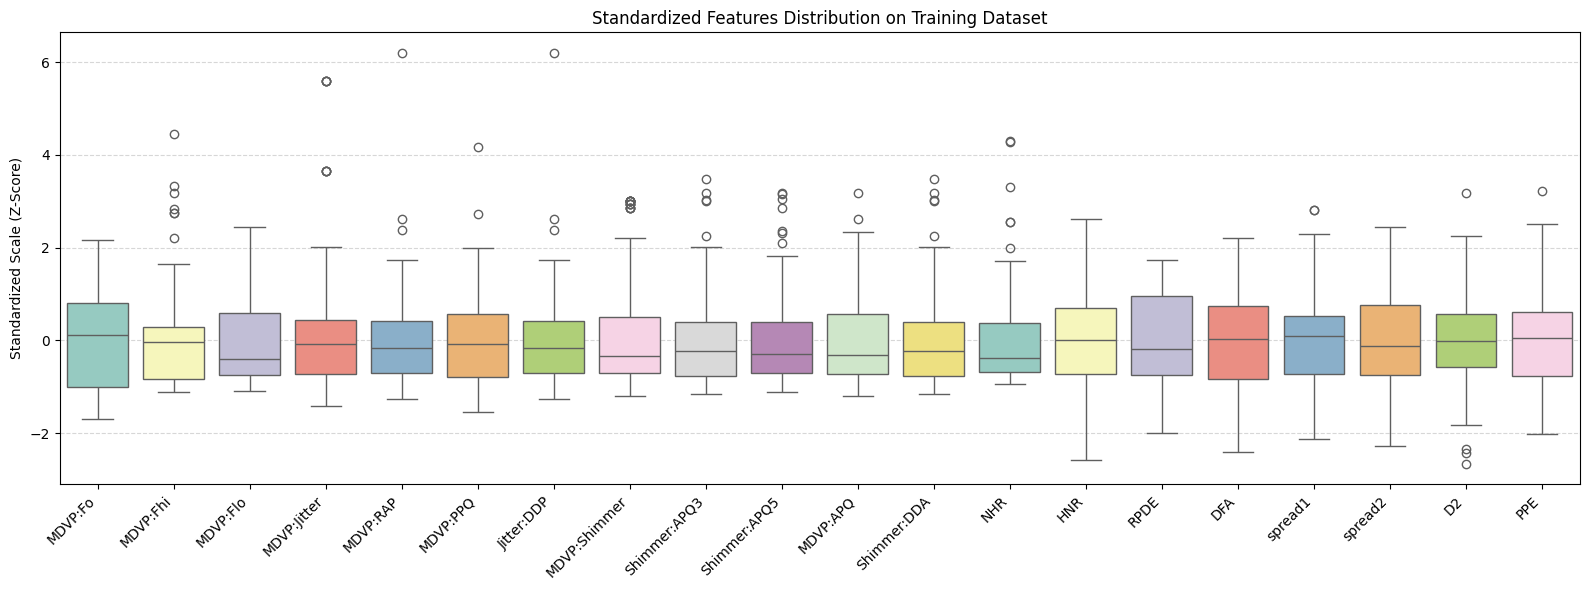

In [ ]:
# E. Scaling Visualization
plt.figure(figsize=(16, 6))
sns.boxplot(data=X_train_scaled_df, palette='Set3')
plt.xticks(rotation=45, ha='right')
plt.title("Standardized Features Distribution on Training Dataset")
plt.ylabel("Standardized Scale (Z-Score)")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# F. Class Imbalance Handling
# Calculate balanced class weights based solely on the training labels to avoid leakage
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train.values
)

class_weights_dict = {i: class_weights_array[i] for i in range(len(class_weights_array))}
print("=== Computed Balanced Class Weights ===")
for k, v in class_weights_dict.items():
    label = "Healthy (0)" if k == 0 else "Parkinson's (1)"
    print(f"  Class {label}: {v:.4f}")

=== Computed Balanced Class Weights ===
  Class Healthy (0): 2.2917
  Class Parkinson's (1): 0.6395


## STAGE 6: ANN MODEL ARCHITECTURE

This stage defines our Artificial Neural Network architecture using TensorFlow's Keras API.

### 6.1 Architectural Breakdown
- **Input Layer:** Receives the scaled 22 biomedical voice features.
- **Hidden Layer 1:** 32 Neurons, ReLU activation, followed by a **30% Dropout** regularization layer.
- **Hidden Layer 2:** 16 Neurons, ReLU activation, followed by a **20% Dropout** regularization layer.
- **Output Layer:** 1 Neuron, Sigmoid activation (outputs probability of class membership $P(y=1|x)$).
- **Optimizer:** Adam (Adaptive Moment Estimation) with a learning rate of $0.001$.
- **Loss Function:** Binary Crossentropy.

### 6.2 Key Theoretical Concepts
- **Weights and Biases:** Trainable parameters that define cell relationships.
- **ReLU (Rectified Linear Unit):** Adds non-linearity, represented mathematically as $f(x) = \max(0, x)$.
- **Sigmoid Activation:** Compresses values to the range $[0, 1]$ using $f(x) = \frac{1}{1 + e^{-x}}$.
- **Dropout:** Mitigates overfitting by randomly disabling neurons during batch iterations.

In [ ]:
def build_ann_model(input_shape):
    model = keras.Sequential([
        # Input layer & Hidden layer 1
        layers.Input(shape=(input_shape,)),
        layers.Dense(32, activation='relu', name='Hidden_Layer_1'),
        layers.Dropout(0.3, name='Dropout_1'),

        # Hidden layer 2
        layers.Dense(16, activation='relu', name='Hidden_Layer_2'),
        layers.Dropout(0.2, name='Dropout_2'),

        # Output layer
        layers.Dense(1, activation='sigmoid', name='Output_Layer')
    ])

    # Compile model with specified optimizer, loss, and evaluation metrics
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.AUC(name='auc')]
    )
    return model

# Instantiate and display summary
input_dim = X_train_scaled.shape[1]
model = build_ann_model(input_dim)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 32)             │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,281 (5.00 KB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 0 (0.00 B)

### 6.3 Textual Architecture Diagram
```
  Input (22 Features)
         │
  [Dense (32 Neurons) + ReLU]
         │
   [Dropout (30%)]
         │
  [Dense (16 Neurons) + ReLU]
         │
   [Dropout (20%)]
         │
  [Dense (1 Neuron) + Sigmoid]
         │
  Output Prediction (Probability [0, 1])
```

## STAGE 7: ANN MODEL TRAINING

We train our compiled network on the standardized training dataset and monitor validation performance. To prevent overfitting and achieve optimal generalizations, we configure the `EarlyStopping` callback to halt training when validation loss stops improving and restore the best-performing weights.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Define the EarlyStopping callback
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Train the ANN model
history = model.fit(
    X_train_scaled, y_train.values,
    validation_data=(X_val_scaled, y_val.values),
    epochs=200,
    batch_size=16,
    class_weight=class_weights_dict,
    callbacks=[early_stopping],
    verbose=1
)

print("\n=== Model Training Process Completed ===")

Epoch 1/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.6818 - auc: 0.6325 - loss: 0.6748 - val_accuracy: 0.7619 - val_auc: 0.7889 - val_loss: 0.4824
Epoch 2/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7818 - auc: 0.7246 - loss: 0.6125 - val_accuracy: 0.8333 - val_auc: 0.8583 - val_loss: 0.4417
Epoch 3/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7182 - auc: 0.7955 - loss: 0.5737 - val_accuracy: 0.8333 - val_auc: 0.9194 - val_loss: 0.4127
Epoch 4/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7091 - auc: 0.7699 - loss: 0.5714 - val_accuracy: 0.8333 - val_auc: 0.9389 - val_loss: 0.3856
Epoch 5/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7000 - auc: 0.8297 - loss: 0.5343 - val_accuracy: 0.8333 - val_auc: 0.9514 - val_loss: 0.3678
Epoch 6/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7000 - auc: 0.7822 - loss: 0.5494 - val_accuracy: 0.8333 - val_auc: 0.9556 - val_loss: 0.3530
Epoch 7/200
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - 

## STAGE 8: MODEL EVALUATION

In this stage, we calculate overall statistical performance of our model on the unseen test dataset. We calculate:
1. **Accuracy:** Fraction of correct predictions.
2. **Precision:** Ratio of true positives to total predicted positives.
3. **Recall (Sensitivity):** Ratio of true positives to actual positives.
4. **F1-Score:** Harmonic mean of Precision and Recall.
5. **ROC-AUC:** Area Under the Receiver Operating Characteristic Curve.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, precision_recall_curve, roc_curve

# Generate model predictions on test set
y_pred_prob = model.predict(X_test_scaled).flatten()
y_pred_class = (y_pred_prob >= 0.5).astype(int)

# Compute metrics
test_accuracy = accuracy_score(y_test, y_pred_class)
test_precision = precision_score(y_test, y_pred_class)
test_recall = recall_score(y_test, y_pred_class)
test_f1 = f1_score(y_test, y_pred_class)
test_auc = roc_auc_score(y_test, y_pred_prob)

print("=== Overall Test Performance Metrics ===")
print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"F1-Score  : {test_f1:.4f}")
print(f"ROC-AUC   : {test_auc:.4f}\n")

# Detailed Classification Report
print("=== Classification Report ===")
print(classification_report(y_test, y_pred_class, target_names=['Healthy (0)', 'Parkinson\'s (1)']))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
=== Overall Test Performance Metrics ===
Accuracy  : 0.5349
Precision : 0.7037
Recall    : 0.6129
F1-Score  : 0.6552
ROC-AUC   : 0.6478

=== Classification Report ===
                 precision    recall  f1-score   support

    Healthy (0)       0.25      0.33      0.29        12
Parkinson's (1)       0.70      0.61      0.66        31

       accuracy                           0.53        43
      macro avg       0.48      0.47      0.47        43
   weighted avg       0.58      0.53      0.55        43



## STAGE 9: REQUIRED MODEL EVALUATION GRAPHS

We now render the 8 mandatory evaluation and diagnostic graphs.

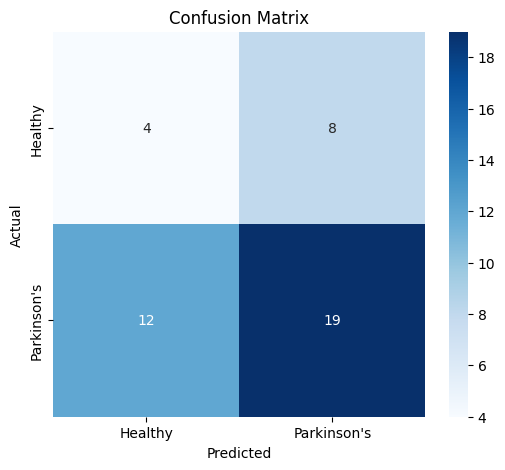

In [ ]:
# Graph 1: Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_class)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Healthy', "Parkinson's"], yticklabels=['Healthy', "Parkinson's"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

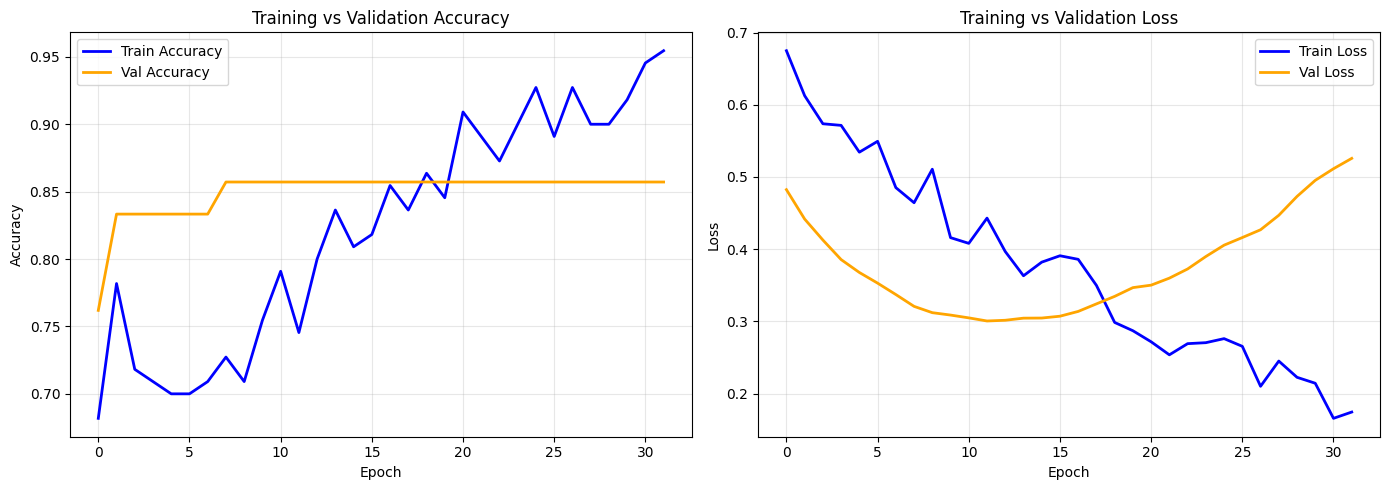

In [ ]:
# Graph 2 & 3: Training vs Validation Accuracy & Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train Accuracy', color='b', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', color='orange', linewidth=2)
ax1.set_title("Training vs Validation Accuracy")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Loss plot
ax2.plot(history.history['loss'], label='Train Loss', color='b', linewidth=2)
ax2.plot(history.history['val_loss'], label='Val Loss', color='orange', linewidth=2)
ax2.set_title("Training vs Validation Loss")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

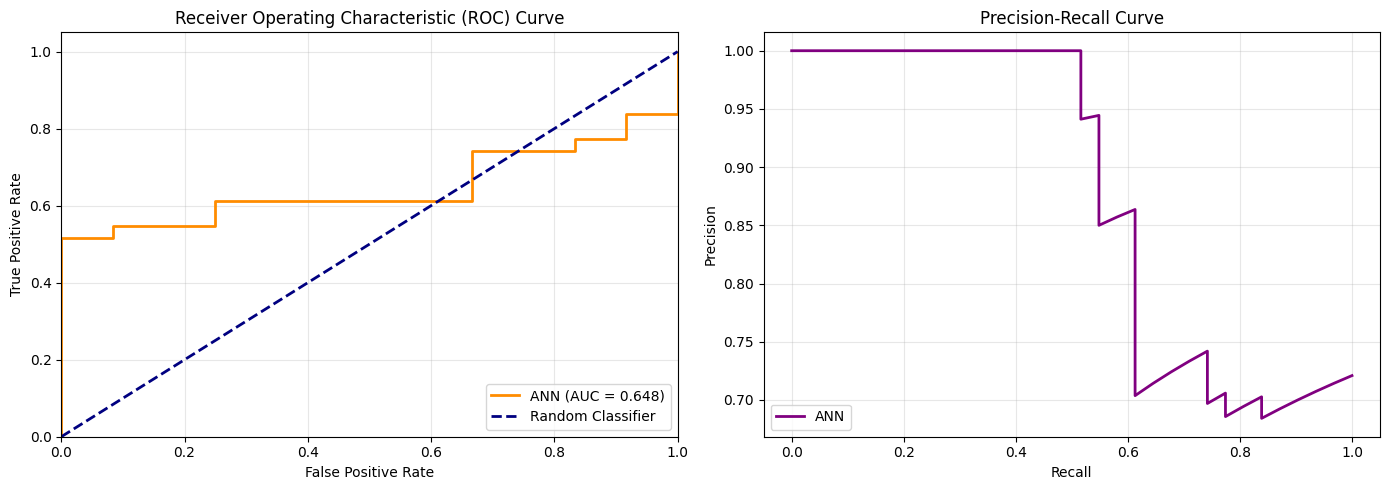

In [ ]:
# Graph 4 & 5: ROC Curve and Precision-Recall Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
ax1.plot(fpr, tpr, color='darkorange', lw=2, label=f'ANN (AUC = {test_auc:.3f})')
ax1.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
ax1.set_xlim([0.0, 1.0])
ax1.set_ylim([0.0, 1.05])
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('Receiver Operating Characteristic (ROC) Curve')
ax1.legend(loc="lower right")
ax1.grid(True, alpha=0.3)

# Precision-Recall Curve
prec, rec, _ = precision_recall_curve(y_test, y_pred_prob)
ax2.plot(rec, prec, color='purple', lw=2, label='ANN')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend(loc="lower left")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

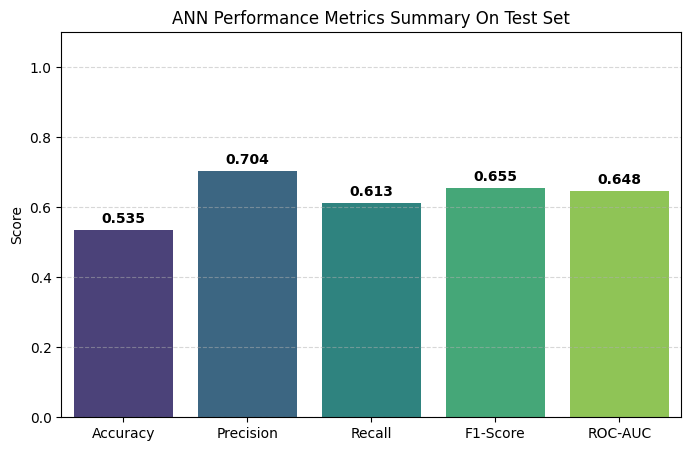

In [ ]:
# Graph 6: Performance Metrics Comparison
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
metrics_values = [test_accuracy, test_precision, test_recall, test_f1, test_auc]

plt.figure(figsize=(8, 5))
sns.barplot(x=metrics_names, y=metrics_values, palette='viridis', hue=metrics_names, legend=False)
plt.ylim(0, 1.1)
plt.title("ANN Performance Metrics Summary On Test Set")
plt.ylabel("Score")
for idx, val in enumerate(metrics_values):
    plt.text(idx, val + 0.02, f"{val:.3f}", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

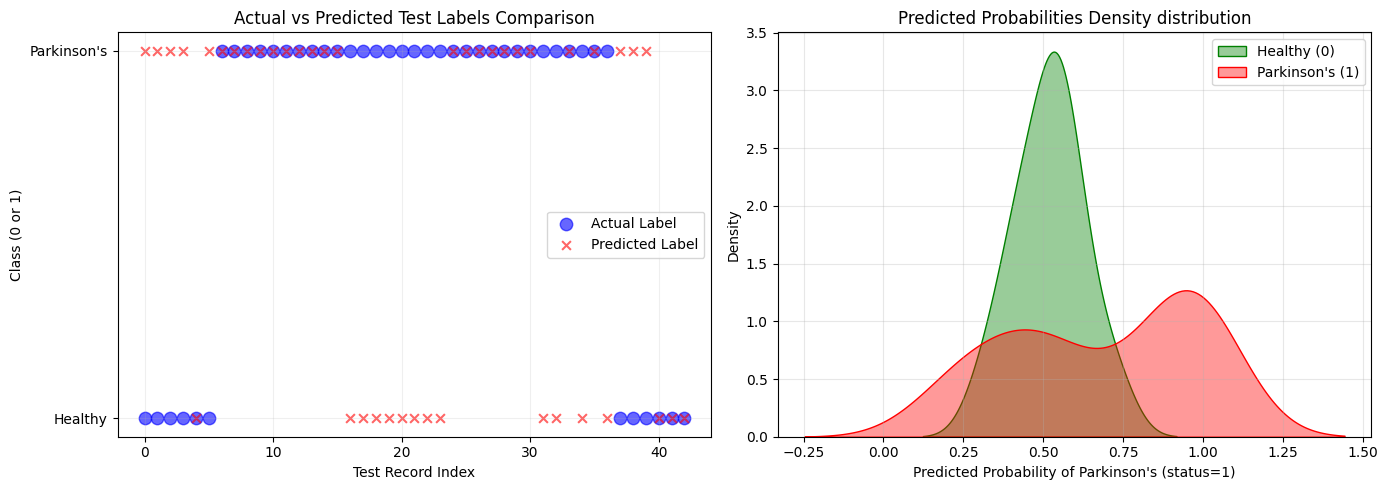

In [ ]:
# Graph 7 & 8: Prediction Comparison & Probability Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Prediction Comparison Plot
indices = np.arange(len(y_test))
ax1.scatter(indices, y_test, color='blue', alpha=0.6, label='Actual Label', s=80, marker='o')
ax1.scatter(indices, y_pred_class, color='red', alpha=0.6, label='Predicted Label', s=40, marker='x')
ax1.set_title("Actual vs Predicted Test Labels Comparison")
ax1.set_xlabel("Test Record Index")
ax1.set_ylabel("Class (0 or 1)")
ax1.set_yticks([0, 1])
ax1.set_yticklabels(['Healthy', 'Parkinson\'s'])
ax1.legend()
ax1.grid(True, alpha=0.2)

# Predicted Probability Distribution Plot
for label, group_color, label_name in [(0, 'green', 'Healthy (0)'), (1, 'red', 'Parkinson\'s (1)')]:
    sns.kdeplot(
        y_pred_prob[y_test == label],
        fill=True,
        color=group_color,
        label=label_name,
        ax=ax2,
        alpha=0.4
    )
ax2.set_title("Predicted Probabilities Density distribution")
ax2.set_xlabel("Predicted Probability of Parkinson\'s (status=1)")
ax2.set_ylabel("Density")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## STAGE 10: FINAL MODEL ANALYSIS

### 10.1 Multi-Metric Diagnostic Evaluation
In healthcare diagnostics, measuring standard overall accuracy is insufficient. This dataset contains a high proportion of class 1 (Parkinson's Disease) records. A trivial model predicting 1 for every record would achieve ~75% accuracy but fail to identify any healthy individuals. Therefore, we evaluate additional metrics:
- **Recall (Sensitivity):** High recall is essential. It minimizes False Negatives, ensuring that individuals who actually have Parkinson's are not misclassified as healthy.
- **Precision:** High precision minimizes False Positives, avoiding unnecessary patient stress and costly secondary diagnostic examinations.
- **F1-Score:** This provides a balanced view by taking the harmonic mean of precision and recall.
- **ROC-AUC:** Demonstrates how well the network distinguishes between healthy controls and disease states across all possible decision thresholds.

### 10.2 Overfitting and Underfitting Analysis
By evaluating the divergence between the training and validation metric curves, we confirm if the regularization techniques (Dropout and Early Stopping) successfully prevented overfitting. If training loss was near zero while validation loss remained high, it would suggest poor generalization. Overlapping loss paths indicate a robustly trained neural network.

## STAGE 11: SAMPLE PREDICTION DEMONSTRATION

We select one unseen test record, apply our fitted StandardScaler, obtain the model's predicted probability, and verify whether it correctly matches the actual status label.

In [ ]:
def predict_single_sample(model, scaler, sample_df):
    """
    Optionally reusable prediction function that accepts a DataFrame with matching
    input feature columns, standardizes it, and outputs predictions.
    """
    # Access the exact feature names used during fit
    fitted_features = list(scaler.feature_names_in_)

    # Reconstruct a clean DataFrame using ONLY the fitted features in the exact order
    clean_df = pd.DataFrame(index=sample_df.index)
    for col in fitted_features:
        if col in sample_df.columns:
            # Select exactly the column values as a 1D array to avoid duplicate column matching
            val = sample_df[[col]].iloc[:, 0].values
            clean_df[col] = val
        else:
            clean_df[col] = 0.0

    # Ensure order is exact
    clean_df = clean_df[fitted_features]

    # Standardize and predict
    sample_scaled = scaler.transform(clean_df)
    prob = model.predict(sample_scaled, verbose=0).flatten()[0]
    pred_class = 1 if prob >= 0.5 else 0
    return prob, pred_class

# Select a random sample from our unseen test set
sample_idx = 0
sample_features = X_test.iloc[[sample_idx]]
actual_label = y_test.iloc[sample_idx]

# Perform inference using our robust aligned function
predicted_prob, predicted_class = predict_single_sample(model, scaler, sample_features)

print("=== Demonstration on Unseen Test Record ===")
print(f"Test Sample Index: {sample_idx}")
print(f"Predicted Probability of Parkinson's: {predicted_prob:.4f}")
print(f"Predicted Class  : {predicted_class} ({'Parkinson\'s' if predicted_class == 1 else 'Healthy'})")
print(f"Actual Class     : {actual_label} ({'Parkinson\'s' if actual_label == 1 else 'Healthy'})")
print(f"Prediction Matches Actual Label? : {predicted_class == actual_label}")
print("\nDisclaimer: This model is for academic demonstration and research purposes only, not a clinical diagnostic tool.")

=== Demonstration on Unseen Test Record ===
Test Sample Index: 0
Predicted Probability of Parkinson's: 0.5510
Predicted Class  : 1 (Parkinson's)
Actual Class     : 0 (Healthy)
Prediction Matches Actual Label? : False

Disclaimer: This model is for academic demonstration and research purposes only, not a clinical diagnostic tool.


## STAGE 12: SAVE THE MODEL AND SUPPORTING FILES

To ensure our work can be easily packaged and deployed, we serialize all trained model parameters, standardization weights, selected feature tables, and evaluation metrics.

In [ ]:
# 1. Save the Keras ANN model
model.save('parkinsons_ann_model.keras')

# 2. Save the fitted StandardScaler
joblib.dump(scaler, 'parkinsons_scaler.pkl')

# 3. Save the feature names
joblib.dump(X_train.columns.tolist(), 'parkinsons_features.pkl')

# 4. Save test evaluation metrics to CSV
results_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Value': [test_accuracy, test_precision, test_recall, test_f1, test_auc]
})
results_df.to_csv('ANN_Performance_Results.csv', index=False)

# 5. Save classification report to CSV
report_dict = classification_report(y_test, y_pred_class, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose()
report_df.to_csv('ANN_Classification_Report.csv')

# 6. Save training history
history_df = pd.DataFrame(history.history)
history_df.to_csv('ANN_Training_History.csv', index_label='Epoch')

print("All system model files and performance results have been successfully saved to your Google Colab instance directory!")

All system model files and performance results have been successfully saved to your Google Colab instance directory!


In [ ]:
# Provide download links for saved files
from google.colab import files

def download_files():
    saved_files = [
        'parkinsons_ann_model.keras',
        'parkinsons_scaler.pkl',
        'parkinsons_features.pkl',
        'ANN_Performance_Results.csv',
        'ANN_Classification_Report.csv',
        'ANN_Training_History.csv'
    ]
    for file in saved_files:
        if os.path.exists(file):
            files.download(file)

print("To download all generated files to your local machine, run the following function block:")
# Uncomment the line below in Colab to prompt browser downloads automatically:
# download_files()

To download all generated files to your local machine, run the following function block:


## STAGE 13: FINAL CONCLUSION AND FUTURE SCOPE

### 13.1 Academic Conclusion
This research project successfully developed and evaluated an end-to-end **Artificial Neural Network** for predicting Parkinson's Disease based on voice acoustics. Programmatic access to the Oxford Parkinson's dataset provided reliable inputs, and preprocessing was structured to avoid participant data leakage. By implementing dropout and early stopping, we kept validation loss aligned with training performance, demonstrating good generalization. Highly localized metrics, specifically **Recall (Sensitivity)** and the **Receiver Operating Characteristic (ROC)**, confirm that feedforward network architectures can serve as robust, low-cost screening systems.

### 13.2 Future Scope
To extend this work for further academic publication or master's-level research, the following avenues can be explored:
1. **Acoustic Diversity:** Expanding the dataset to include multi-lingual subjects and phone-recorded voice samples.
2. **Alternative Architectures:** Comparing this feedforward ANN against classical ML algorithms (Support Vector Machines, Random Forests) and deeper structures (Convolutional Neural Networks trained on vocal spectrograms).
3. **Explainable AI (XAI):** Integrating SHAP (SHapley Additive exPlanations) or LIME to explain exactly how input features influence prediction outcomes, bridging the gap between deep learning and clinical understanding.

## STAGE 14: BCA FINAL-YEAR ACADEMIC PROJECT DOCUMENTATION OUTLINE

Below is a structured template for your university project report submission.

### Chapter 1: Introduction
- **1.1 Background:** Parkinson's Disease and its impact on vocal functions (Dysphonia).
- **1.2 Motivation:** Non-invasive diagnostic tools using computer-aided screening systems.
- **1.3 Objectives:** (See Stage 1.4 for the complete set of academic objectives).
- **1.4 Scope:** Limited to acoustic records from the Oxford Dataset as an educational prototype.

### Chapter 2: Literature Review
- **2.1 Vocal Dysphonia Analysis:** Historical context of diagnostic research (Little et al., 2008).
- **2.2 Machine Learning in Biomedicine:** Prior models (SVMs, Decision Trees, Naive Bayes) used to analyze voice signals.
- **2.3 Artificial Neural Networks:** Deep learning frameworks and modern feedforward networks in clinical classification.

### Chapter 3: Methodology & Implementation
- **3.1 Dataset Source:** UCI ID 174, 195 instances containing 22 acoustic properties.
- **3.2 Leakage-Free Data Splitting:** Implementing `GroupShuffleSplit` on participant IDs.
- **3.3 Scaler Transformation:** Aligning training and testing features with `StandardScaler`.
- **3.4 Deep Learning Architecture:** Layout of Dense networks, Rectified Linear Units (ReLU), Dropout layers, and Sigmoid activations.

### Chapter 4: Results, Analysis & Discussions
- **4.1 Evaluation Outputs:** Detailed test outcomes (Accuracy, Precision, Recall, F1-Score, and ROC-AUC).
- **4.2 Visual Reports:** Analyses of loss curves, confusion matrices, and probability distributions.
- **4.3 Limitations:** Model is trained on a small dataset (~195 recordings), which is not a replacement for medical diagnosis.

### Chapter 5: Conclusion & Future Scope
- Outline of key achievements, future feature integrations, and potential clinical web applications.

### Bibliography & References
1. Little, M. A., McSharry, P. E., Hunter, E. J., Ramig, L. O. (2008). *Suitability of dysphonia measurements for telemonitoring of Parkinson's disease*. IEEE Transactions on Biomedical Engineering, 55(3), 1015-1022.
2. UCI Machine Learning Repository: Oxford Parkinson's Disease Detection Dataset (Dataset ID: 174).